In [294]:
# Import Pandas

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

# Load the dataset

df = pd.read_csv('/content/CAR DETAILS FROM CAR DEKHO.csv')

# Display first five records

print("First five records:")
display(df.head())

Libraries imported successfully!
First five records:


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


In [295]:
# Check dataset dimensions

print("Number of rows and columns:")
print(df.shape)

# Display column names

print("\nColumn names:")
print(df.columns.tolist())

# Display dataset information

print("\nDataset information:")
df.info()

Number of rows and columns:
(4340, 8)

Column names:
['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   name           4340 non-null   object
 1   year           4340 non-null   int64 
 2   selling_price  4340 non-null   int64 
 3   km_driven      4340 non-null   int64 
 4   fuel           4340 non-null   object
 5   seller_type    4340 non-null   object
 6   transmission   4340 non-null   object
 7   owner          4340 non-null   object
dtypes: int64(3), object(5)
memory usage: 271.4+ KB


In [296]:
# Check missing values in each column

print("Missing Values:")

print(df.isnull().sum())

Missing Values:
name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64


In [297]:
# Check data types

print("Data types of columns:")

print(df.dtypes)

Data types of columns:
name             object
year              int64
selling_price     int64
km_driven         int64
fuel             object
seller_type      object
transmission     object
owner            object
dtype: object


In [298]:
# Statistical summary of numerical columns

print("Statistical Summary:")

display(df.describe())

Statistical Summary:


,year,selling_price,km_driven
count,4340.000000,4.340000e+03,4340.000000
mean,2013.090783,5.041273e+05,66215.777419
std,4.215344,5.785487e+05,46644.102194
min,1992.000000,2.000000e+04,1.000000
25%,2011.000000,2.087498e+05,35000.000000
50%,2014.000000,3.500000e+05,60000.000000
75%,2016.000000,6.000000e+05,90000.000000
max,2020.000000,8.900000e+06,806599.000000


In [299]:
# Outlier detection using IQR

columns = ['selling_price', 'km_driven', 'year']

for col in columns:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower) | (df[col] > upper)
    ]

    print("\nColumn:", col)
    print("Lower limit:", lower)
    print("Upper limit:", upper)
    print("Number of outliers:", len(outliers))


Column: selling_price
Lower limit: -378125.625
Upper limit: 1186875.375
Number of outliers: 271

Column: km_driven
Lower limit: -47500.0
Upper limit: 172500.0
Number of outliers: 110

Column: year
Lower limit: 2003.5
Upper limit: 2023.5
Number of outliers: 105


In [300]:
# Check unique categories

categorical_columns = [
    'fuel',
    'seller_type',
    'transmission',
    'owner'
]

for col in categorical_columns:

    print("\n", col)
    print(df[col].value_counts())


 fuel
fuel
Diesel      2153
Petrol      2123
CNG           40
LPG           23
Electric       1
Name: count, dtype: int64

 seller_type
seller_type
Individual          3244
Dealer               994
Trustmark Dealer     102
Name: count, dtype: int64

 transmission
transmission
Manual       3892
Automatic     448
Name: count, dtype: int64

 owner
owner
First Owner             2832
Second Owner            1106
Third Owner              304
Fourth & Above Owner      81
Test Drive Car            17
Name: count, dtype: int64


In [301]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate records:")
print(df.duplicated().sum())

Missing values:
name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64

Duplicate records:
763


In [302]:
# Step 1: Create a copy of the original dataset

df_original = df.copy()

# Step 2: Remove duplicate records

df_clean = df.drop_duplicates().copy()

# Step 3: Compare dataset sizes

print("Before cleaning:", len(df_original))
print("After cleaning:", len(df_clean))

print("Duplicates removed:",
      len(df_original) - len(df_clean))

# Step 4: Verify duplicates

print("Remaining duplicates:",
      df_clean.duplicated().sum())

Before cleaning: 4340
After cleaning: 3577
Duplicates removed: 763
Remaining duplicates: 0


In [303]:
# Check data types after cleaning

print(df_clean.dtypes)

# Check unique values in categorical columns

for col in ['fuel', 'seller_type',
            'transmission', 'owner']:

    print("\n", col)
    print(df_clean[col].unique())

name             object
year              int64
selling_price     int64
km_driven         int64
fuel             object
seller_type      object
transmission     object
owner            object
dtype: object

 fuel
['Petrol' 'Diesel' 'CNG' 'LPG' 'Electric']

 seller_type
['Individual' 'Dealer' 'Trustmark Dealer']

 transmission
['Manual' 'Automatic']

 owner
['First Owner' 'Second Owner' 'Fourth & Above Owner' 'Third Owner'
 'Test Drive Car']


In [304]:
# Outlier detection on cleaned dataset

columns = ['selling_price', 'km_driven', 'year']

for col in columns:

    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df_clean[
        (df_clean[col] < lower) |
        (df_clean[col] > upper)
    ]

    print("\nColumn:", col)
    print("Lower limit:", lower)
    print("Upper limit:", upper)
    print("Outliers:", len(outliers))


Column: selling_price
Lower limit: -400000.0
Upper limit: 1200000.0
Outliers: 170

Column: km_driven
Lower limit: -45000.0
Upper limit: 171000.0
Outliers: 106

Column: year
Lower limit: 2001.0
Upper limit: 2025.0
Outliers: 37


In [305]:
print("Lowest priced cars:")
display(df_clean.nsmallest(5, 'selling_price'))

print("Highest priced cars:")
display(df_clean.nlargest(5, 'selling_price'))

print("Highest kilometres driven:")
display(df_clean.nlargest(5, 'km_driven'))

Lowest priced cars:


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
2662,Ford Ikon 1.6 ZXI NXt,2005,20000,25000,Petrol,Individual,Manual,Second Owner
2495,Ford Ikon 1.4 ZXi,2000,22000,42743,Petrol,Dealer,Manual,Third Owner
2444,Maruti 800 EX,2004,30000,60000,Petrol,Individual,Manual,Third Owner
1832,Tata Nano LX SE,2012,35000,35000,Petrol,Individual,Manual,Third Owner
2849,Tata Nano Std BSII,2009,35000,50000,Petrol,Individual,Manual,Third Owner


Highest priced cars:


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
3872,Audi RS7 2015-2019 Sportback Performance,2016,8900000,13000,Petrol,Dealer,Automatic,First Owner
89,Mercedes-Benz S-Class S 350d Connoisseurs Edition,2017,8150000,6500,Diesel,Dealer,Automatic,First Owner
3969,Mercedes-Benz GLS 2016-2020 350d 4MATIC,2016,5500000,77350,Diesel,Dealer,Automatic,First Owner
555,BMW X5 xDrive 30d xLine,2019,4950000,30000,Diesel,Dealer,Automatic,First Owner
3453,BMW 5 Series 520d Luxury Line,2018,4800000,9422,Diesel,Individual,Automatic,First Owner


Highest kilometres driven:


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
1243,Maruti Swift VXI BSIII,2009,250000,806599,Petrol,Dealer,Manual,First Owner
525,Maruti SX4 S Cross DDiS 320 Delta,2016,665000,560000,Diesel,Dealer,Manual,First Owner
3679,Toyota Innova 2.5 G (Diesel) 7 Seater BS IV,2006,400000,400000,Diesel,Individual,Manual,Third Owner
69,Chevrolet Tavera Neo LS B3 - 7(C) seats BSIII,2010,280000,350000,Diesel,Individual,Manual,Second Owner
2394,Toyota Innova 2.5 V Diesel 8-seater,2009,350000,350000,Diesel,Individual,Manual,First Owner


In [306]:
# Final outlier count analysis

for col in ['selling_price', 'km_driven', 'year']:

    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = (
        (df_clean[col] < lower) |
        (df_clean[col] > upper)
    ).sum()

    print("\nFeature:", col)
    print("IQR:", IQR)
    print("Lower boundary:", lower)
    print("Upper boundary:", upper)
    print("Outlier count:", count)


Feature: selling_price
IQR: 400000.0
Lower boundary: -400000.0
Upper boundary: 1200000.0
Outlier count: 170

Feature: km_driven
IQR: 54000.0
Lower boundary: -45000.0
Upper boundary: 171000.0
Outlier count: 106

Feature: year
IQR: 6.0
Lower boundary: 2001.0
Upper boundary: 2025.0
Outlier count: 37


In [307]:
# Create a brand column

df_clean['brand'] = df_clean['name'].str.split().str[0]

# Calculate car age using dataset reference year

reference_year = 2021

df_clean['car_age'] = reference_year - df_clean['year']

# Display the updated dataset

display(df_clean.head())

print("Updated columns:")
print(df_clean.columns.tolist())

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,brand,car_age
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner,Maruti,14
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner,Maruti,14
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner,Hyundai,9
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner,Datsun,4
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner,Honda,7


Updated columns:
['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner', 'brand', 'car_age']


In [308]:
# Create a brand column

df_clean['brand'] = df_clean['name'].str.split().str[0]

# Calculate car age using dataset reference year

reference_year = 2021

df_clean['car_age'] = reference_year - df_clean['year']

# Display the updated dataset

display(df_clean.head())

print("Updated columns:")
print(df_clean.columns.tolist())

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,brand,car_age
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner,Maruti,14
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner,Maruti,14
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner,Hyundai,9
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner,Datsun,4
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner,Honda,7


Updated columns:
['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner', 'brand', 'car_age']


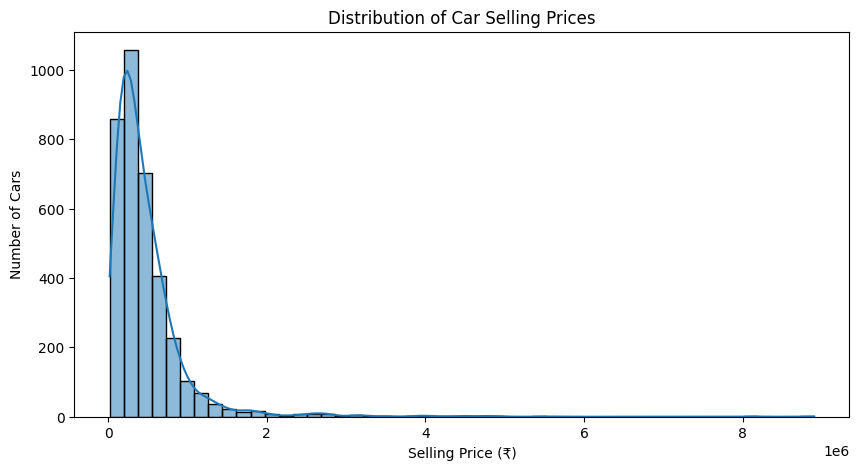

In [309]:
# Graph 1: Distribution of Car Prices

plt.figure(figsize=(10, 5))

sns.histplot(
    df_clean['selling_price'],
    bins=50,
    kde=True
)

plt.title('Distribution of Car Selling Prices')
plt.xlabel('Selling Price (₹)')
plt.ylabel('Number of Cars')

plt.show()

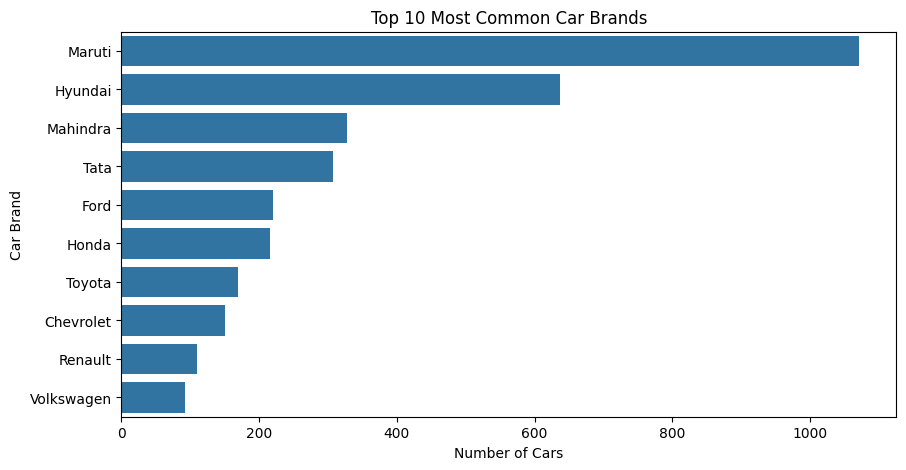

In [310]:
# Graph 2: Top 10 Car Brands

top_brands = df_clean['brand'].value_counts().head(10)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=top_brands.values,
    y=top_brands.index
)

plt.title('Top 10 Most Common Car Brands')
plt.xlabel('Number of Cars')
plt.ylabel('Car Brand')

plt.show()

In [311]:
for col in ['selling_price', 'km_driven', 'year']:

    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = (
        (df_clean[col] < lower) |
        (df_clean[col] > upper)
    ).sum()

    print(col, "Outliers:", count)

selling_price Outliers: 170
km_driven Outliers: 106
year Outliers: 37


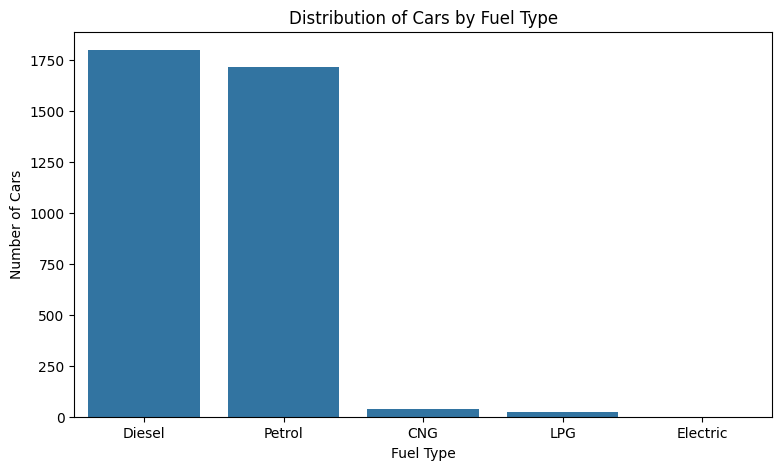

In [312]:
# Graph 3: Fuel Type Distribution

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df_clean,
    x='fuel',
    order=df_clean['fuel'].value_counts().index
)

plt.title('Distribution of Cars by Fuel Type')
plt.xlabel('Fuel Type')
plt.ylabel('Number of Cars')

plt.show()

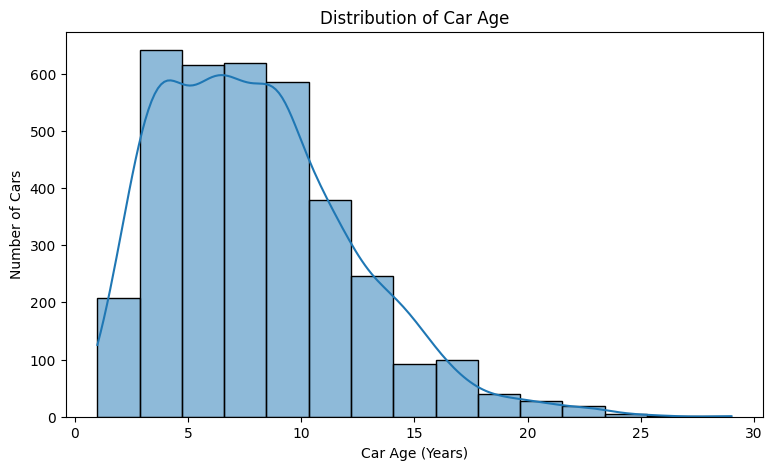

In [313]:
# Graph 4: Distribution of Car Age

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df_clean,
    x='car_age',
    bins=15,
    kde=True
)

plt.title('Distribution of Car Age')
plt.xlabel('Car Age (Years)')
plt.ylabel('Number of Cars')

plt.show()

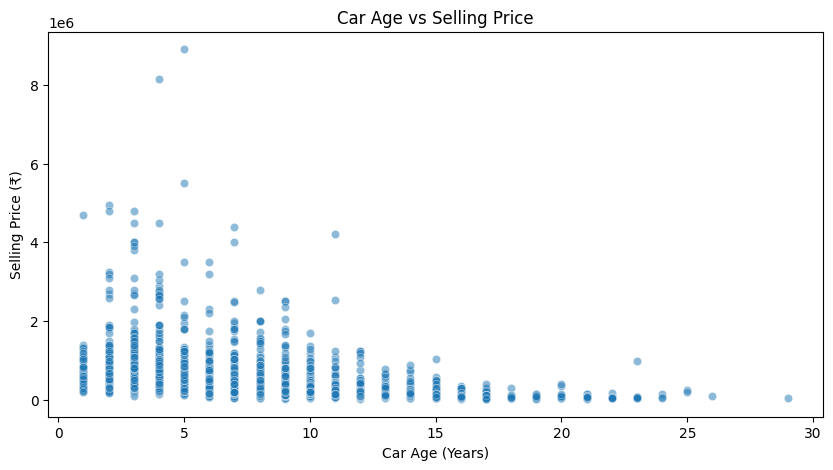

In [314]:
# Graph 5: Car Age vs Selling Price

plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=df_clean,
    x='car_age',
    y='selling_price',
    alpha=0.5
)

plt.title('Car Age vs Selling Price')
plt.xlabel('Car Age (Years)')
plt.ylabel('Selling Price (₹)')

plt.show()

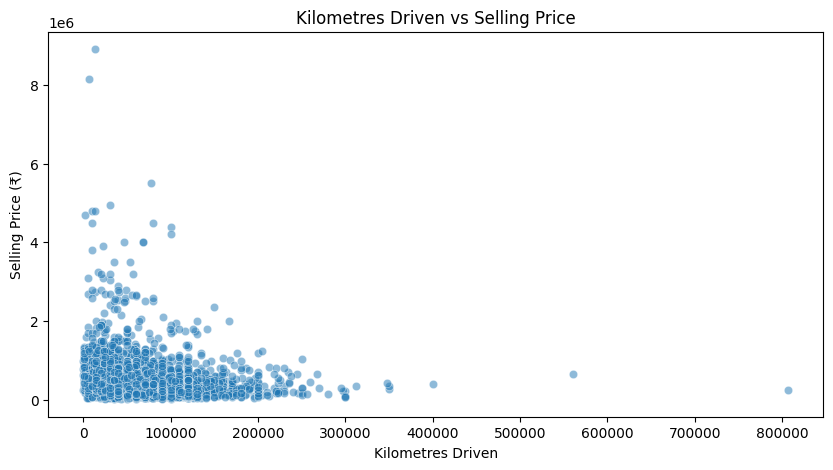

In [315]:
# Graph 6: KM Driven vs Selling Price

plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=df_clean,
    x='km_driven',
    y='selling_price',
    alpha=0.5
)

plt.title('Kilometres Driven vs Selling Price')
plt.xlabel('Kilometres Driven')
plt.ylabel('Selling Price (₹)')

plt.show()

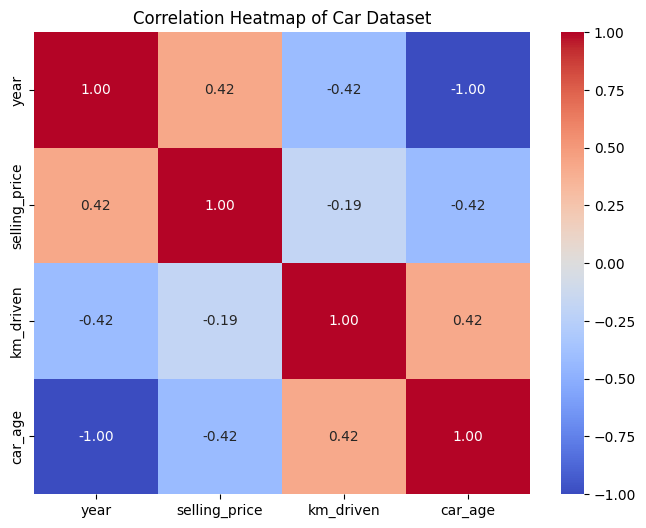

In [316]:
# Graph 7: Correlation Heatmap

numeric_data = df_clean[
    ['year', 'selling_price', 'km_driven', 'car_age']
]

correlation = numeric_data.corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap of Car Dataset')

plt.show()

In [317]:
# FINAL DATA ANALYSIS

print("1. DATASET OVERVIEW")
print("Total cars:", len(df_clean))
print("Total columns:", len(df_clean.columns))

print("\n2. AVERAGE SELLING PRICE")
print("₹", round(df_clean['selling_price'].mean(), 2))

print("\n3. MOST COMMON CAR BRANDS")
print(df_clean['brand'].value_counts().head(5))

print("\n4. FUEL TYPE COUNTS")
print(df_clean['fuel'].value_counts())

print("\n5. AVERAGE PRICE BY FUEL TYPE")
print(df_clean.groupby('fuel')['selling_price'].mean().round(2))

print("\n6. AVERAGE PRICE BY TRANSMISSION")
print(df_clean.groupby('transmission')['selling_price'].mean().round(2))

print("\n7. AVERAGE PRICE BY OWNER TYPE")
print(df_clean.groupby('owner')['selling_price'].mean().round(2))

print("\n8. CORRELATION WITH SELLING PRICE")
print(
    df_clean[
        ['year', 'car_age', 'km_driven', 'selling_price']
    ].corr()['selling_price'].round(2)
)

1. DATASET OVERVIEW
Total cars: 3577
Total columns: 10

2. AVERAGE SELLING PRICE
₹ 473912.54

3. MOST COMMON CAR BRANDS
brand
Maruti      1072
Hyundai      637
Mahindra     328
Tata         308
Ford         220
Name: count, dtype: int64

4. FUEL TYPE COUNTS
fuel
Diesel      1800
Petrol      1717
CNG           37
LPG           22
Electric       1
Name: count, dtype: int64

5. AVERAGE PRICE BY FUEL TYPE
fuel
CNG         273162.08
Diesel      614001.07
Electric    310000.00
LPG         171818.14
Petrol      335344.34
Name: selling_price, dtype: float64

6. AVERAGE PRICE BY TRANSMISSION
transmission
Automatic    1274955.11
Manual        397365.75
Name: selling_price, dtype: float64

7. AVERAGE PRICE BY OWNER TYPE
owner
First Owner             565385.45
Fourth & Above Owner    181213.29
Second Owner            341954.14
Test Drive Car          954293.94
Third Owner             266142.21
Name: selling_price, dtype: float64

8. CORRELATION WITH SELLING PRICE
year             0.42
car_age     

In [318]:
# Export cleaned dataset to CSV

df_clean.to_csv('cleaned_cars_dataset.csv', index=False)

print("Cleaned dataset exported successfully!")

Cleaned dataset exported successfully!
